In [12]:
import os
from pathlib import Path
from dotenv import load_dotenv

import pandas as pd
load_dotenv(override=True)
import matplotlib.pyplot as plt

In [7]:
data_repo_env = os.getenv("DATA_REPO_PATH")
DATA_REPO_DIR = Path(data_repo_env)

weekstats = pd.read_csv(DATA_REPO_DIR / "GW2" / "playermatchstats.csv")
players = pd.read_csv(DATA_REPO_DIR / "GW2" / "players.csv")


In [2]:
weekstats = pd.read_csv("FPL-Core-Insights/data/2026-2027/By Tournament/Premier League/GW2/playermatchstats.csv")
players = pd.read_csv("FPL-Core-Insights/data/2026-2027/By Tournament/Premier League/GW2/players.csv")

In [8]:
def match_stats (match_id, team1, team2):
    match = weekstats[
        (weekstats["match_id"] == match_id) & (weekstats["minutes_played"] > 0)
    ].reset_index(drop=True)

    match_players = players[(players["team_code"] == team1) | (players["team_code"] == team2)].reset_index(drop=True)
    match["name"] = match["player_id"].map(
        match_players.set_index("player_id")["web_name"]
    )
    match["team_code"] = match["player_id"].map(
        players.set_index("player_id")["team_code"]
    )
    return match

In [9]:
def match_plot(match, param1, param2):
    x_val_s = match[match["team_code"] == 6][param1]
    y_val_s = match[match["team_code"] == 6][param2]

    x_val_b = match[match["team_code"] == 4][param1]
    y_val_b = match[match["team_code"] == 4][param2]
    
    plt.figure(figsize=(15, 10))
    plt.scatter(x_val_s, y_val_s, alpha=0.6, color="grey")
    plt.scatter(x_val_b, y_val_b, alpha=0.6, color="black")

    # Add annotations
    for _, row in match.iterrows():
        plt.annotate(
            row["name"], 
            (row[param1], row[param2]),
            xytext=(3, 3), 
            textcoords="offset points",
            fontsize=9
        )

    plt.ylabel('Distance Covered')
    plt.xlabel('Final Third Passes')
    plt.title("Final Third Passes vs Distance Covered")
    plt.grid(color='k', linestyle='-', linewidth=.2)
    plt.show()

In [10]:
match = match_stats('26-27-prem-tottenham-hotspur-vs-newcastle-united', 6, 4)

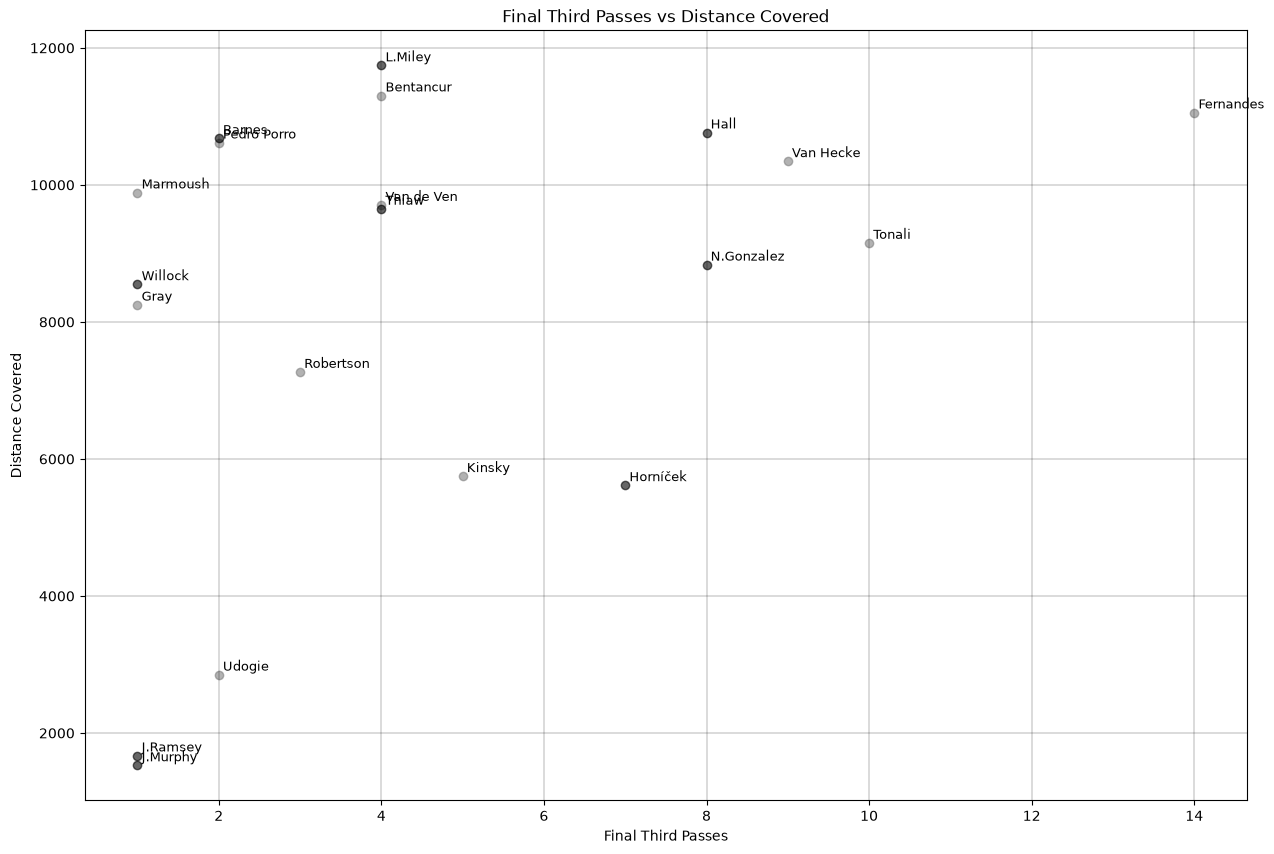

In [13]:
plot = match_plot(match, 'final_third_passes', 'distance_covered')